# Project 10: Overfitting and Underfitting Analysis

**Name:** Syahrul

**Objective:** Build neural networks with different levels of complexity using the Iris dataset and compare their training and testing performance.

## Introduction

Underfitting happens when a model is too simple to learn patterns properly. Overfitting happens when a model learns the training data very closely but performs worse on unseen data. This experiment compares three neural network architectures using the same data split.

## Task 1: Load and Prepare the Iris Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

np.random.seed(42)

iris = load_iris()
X = iris.data
y = iris.target

data = pd.DataFrame(X, columns=iris.feature_names)
data["species"] = [iris.target_names[i] for i in y]

display(data.head())
print("Dataset shape:", data.shape)
print("Classes:", iris.target_names)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)
Classes: ['setosa' 'versicolor' 'virginica']


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 112
Testing samples: 38


## Task 1: Build Models with Different Architectures

The models use the same training and testing data. The small model has very few neurons, the medium model has a moderate number, and the large model has more neurons and more training epochs.

In [3]:
def build_model(neurons):
    model = Sequential([
        Dense(neurons, activation="relu", input_shape=(4,)),
        Dense(3, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.01),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_configs = {
    "Small model": {"neurons": 1, "epochs": 15},
    "Medium model": {"neurons": 8, "epochs": 60},
    "Large model": {"neurons": 64, "epochs": 250}
}

models = {}
histories = {}
results = []

for name, config in model_configs.items():
    model = build_model(config["neurons"])
    history = model.fit(
        X_train, y_train,
        epochs=config["epochs"],
        batch_size=8,
        validation_split=0.2,
        verbose=0
    )

    train_loss, train_accuracy = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

    models[name] = model
    histories[name] = history
    results.append({
        "Model": name,
        "Neurons": config["neurons"],
        "Epochs": config["epochs"],
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Training Loss": train_loss,
        "Testing Loss": test_loss,
        "Accuracy Gap": train_accuracy - test_accuracy
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Model,Neurons,Epochs,Training Accuracy,Testing Accuracy,Training Loss,Testing Loss,Accuracy Gap
0,Small model,1,15,0.8036,0.8158,0.4979,0.5171,-0.0122
1,Medium model,8,60,0.9643,0.9211,0.0809,0.1876,0.0432
2,Large model,64,250,0.9732,0.8421,0.4771,2.0724,0.1311


## Task 2: Compare Training and Testing Performance

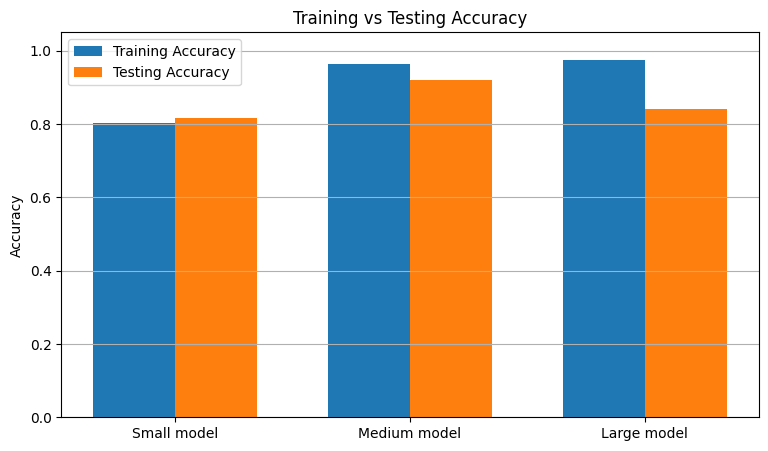

In [4]:
plt.figure(figsize=(9, 5))
x = np.arange(len(results_df))
width = 0.35
plt.bar(x - width / 2, results_df["Training Accuracy"], width, label="Training Accuracy")
plt.bar(x + width / 2, results_df["Testing Accuracy"], width, label="Testing Accuracy")
plt.xticks(x, results_df["Model"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.grid(axis="y")
plt.show()

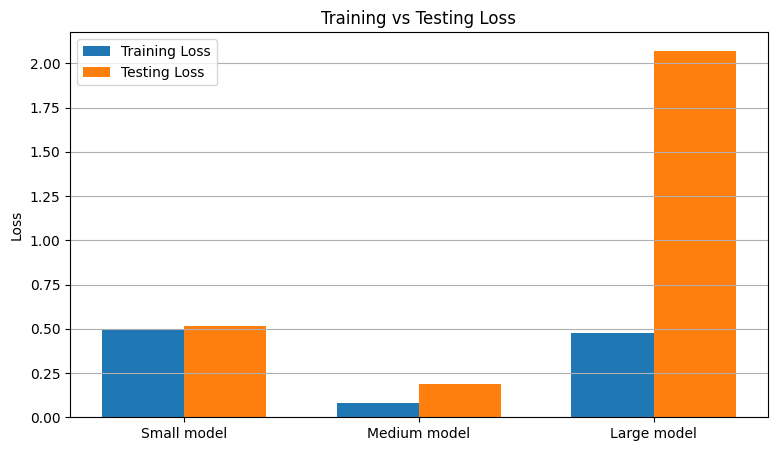

In [5]:
plt.figure(figsize=(9, 5))
x = np.arange(len(results_df))
width = 0.35
plt.bar(x - width / 2, results_df["Training Loss"], width, label="Training Loss")
plt.bar(x + width / 2, results_df["Testing Loss"], width, label="Testing Loss")
plt.xticks(x, results_df["Model"])
plt.ylabel("Loss")
plt.title("Training vs Testing Loss")
plt.legend()
plt.grid(axis="y")
plt.show()

## Training Curves

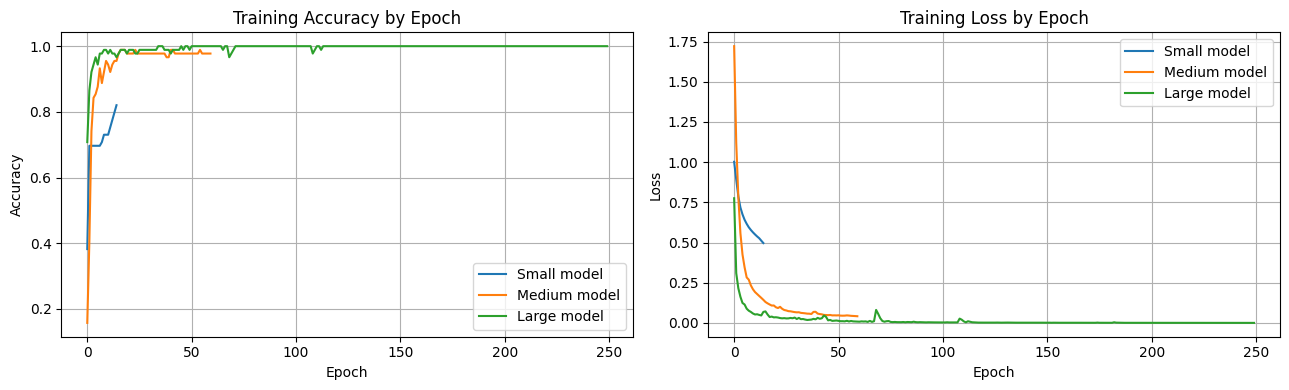

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in histories.items():
    axes[0].plot(history.history["accuracy"], label=name)
    axes[1].plot(history.history["loss"], label=name)

axes[0].set_title("Training Accuracy by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Training Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Task 3: Identify Underfitting, Appropriate Fitting, and Overfitting

In [7]:
for _, row in results_df.iterrows():
    gap = row["Accuracy Gap"]
    train_acc = row["Training Accuracy"]
    test_acc = row["Testing Accuracy"]

    if train_acc < 0.85 and test_acc < 0.85:
        label = "Possible underfitting"
    elif gap > 0.10 and train_acc > test_acc:
        label = "Possible overfitting"
    else:
        label = "Reasonable fit on this split"

    print(f'{row["Model"]}: {label} (train={train_acc:.3f}, test={test_acc:.3f}, gap={gap:.3f})')

best_model_name = results_df.loc[results_df["Testing Accuracy"].idxmax(), "Model"]
print("\nHighest testing accuracy in this run:", best_model_name)

Small model: Possible underfitting (train=0.804, test=0.816, gap=-0.012)
Medium model: Reasonable fit on this split (train=0.964, test=0.921, gap=0.043)
Large model: Possible overfitting (train=0.973, test=0.842, gap=0.131)

Highest testing accuracy in this run: Medium model


## Discussion

Low training and testing performance can indicate underfitting. Very high training performance with noticeably lower testing performance can indicate overfitting. Good testing accuracy with a small gap between training and testing performance suggests better generalization. These are clues, so use the measured results from your run.

## Methods to Improve the Model

- To reduce underfitting, use a more suitable architecture or train for more epochs.
- To reduce overfitting, use a smaller network, dropout, regularization, early stopping, or more training data.
- Choose a model based on testing performance as well as training performance.

## Result

Three neural network architectures were trained on the Iris dataset using the same training and testing split. Their accuracy, loss values, and training curves were compared to look for signs of underfitting, reasonable fitting, and overfitting.

## Conclusion

The experiment shows that model complexity affects learning and generalization. A model that is too simple may not learn the data well, while a more complex model may fit the training data closely without improving test performance. The most suitable model should be selected by considering both training and testing results.